# 02 - No-show prediction (CRISP-DM phases 4 and 5)

This notebook takes over `Prediction_No_Show.ipynb` of the conference paper: same split, same SMOTE, same four models and hyperparameter grids, same metrics computed the same way (`utils_ml.py`). The changes are announced in a **Correction** box where they act:

1. `discontinued` and `service_time` are not predictors any more (notebook 01, section 3.6).
2. SMOTE and the scaler are inside the cross-validation (a pipeline), so that the synthetic no-shows of a fold are never used to score that fold.
3. The decision threshold is chosen on a validation set (part of the training set), never on the test set.
4. The MLP stops on its own validation data, not on the test set.
5. The probabilities are calibrated on the validation set (Platt scaling) before the optimisation (notebook 04).
6. The categorical variables with many values (zip, sta3n, state, stopcode) are target-encoded instead of integer codes, whose order means nothing (zip 437 is not "between" 436 and 438).
7. StandardScaler instead of MinMaxScaler: with MinMaxScaler and batches of 256 the MLP only predicted "show" (pilot run on 10 % of the consultations); the tree models are not affected by the scaling.

## Outline
- [0 - Parameters](#0)
- [1 - Data and split](#1)
- [2 - Models](#2): [Random Forest](#2.1), [XGBoost](#2.2), [AdaBoost](#2.3), [MLP](#2.4)
- [3 - Comparison of the models](#3)
- [4 - Probabilities for the scheduling model](#4)

In [1]:
import sys
sys.path.insert(0, "..")          # utils_ml.py is at the root of the repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
import xgboost as xgb
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from utils_ml import *

<a name="0"></a>
## 0 - Parameters

Every choice of this notebook is set in the cell below, with its reason.

In [2]:
DATA_PATH = "../data/data_prep.parquet"      # written by 01_data_preparation.ipynb
SPLIT_PATH = "../runs/pilot_split.parquet"         # train / validation / test of each consultation, reused by notebook 03
SCORES_PATH = "../runs/pilot_test_scores.parquet"  # no-show probabilities of the test consultations, read by notebook 04
TARGET = "NoShow"
NOT_PREDICTORS = ["service_time"]             # target of notebook 03, known only after the consultation

# Share of the consultations used: 0.1 for a pilot run, 1.0 for the final run.
SAMPLE_FRACTION = 0.1
RANDOM_STATE = 0                              # as in the paper

# Trained models are saved here (not versioned: large) and loaded instead of trained when the
# notebook is run again, for a quick restart and to reproduce the results with the same models.
MODELS_DIR = "../runs/pilot_models/no_show"
RETRAIN = False                               # True: train again even if a saved model exists

# Categorical variables with many values (zip 910, sta3n 130, state 66, stopcode 36). Each value is
# replaced by the no-show rate observed for it in the train set (target encoding, smoothed towards
# the overall rate for rare values). On the train set it is computed by 5-fold cross-fitting, so a
# consultation never sees its own outcome; validation and test use the rates of the whole train set.
CATEGORICAL = ["sta3n", "stopcode", "zip", "state"]
TARGET_ENCODER = dict(target_type="binary", smooth="auto", cv=5, shuffle=True, random_state=RANDOM_STATE)

TEST_SIZE = 0.3                               # as in the paper: 70 % train, 30 % test, stratified
VALIDATION_SIZE = 0.15                        # Correction: share of the train set kept aside to choose the threshold
SMOTE_RATIO = 0.33                            # as in the paper: after SMOTE, no-shows = 33 % of the shows (train only)
CV_FOLDS = 3                                  # as in the paper
SCORING = "f1_macro"                          # the models are optimised for the F1 score, averaged as in the paper's metrics
THRESHOLDS = np.round(np.arange(0.05, 0.96, 0.01), 2)   # candidate decision thresholds

# Hyperparameter grids of the paper (Prediction_No_Show.ipynb).
GRID_RF = {"n_estimators": [100], "max_depth": [10, 15, 20], "min_samples_split": [2, 5],
           "min_samples_leaf": [2, 4], "max_features": ["sqrt"], "class_weight": ["balanced"]}
GRID_XGB = {"n_estimators": [1000], "max_depth": [20, 25], "min_child_weight": [2], "gamma": [0.3],
            "subsample": [0.4], "reg_alpha": [0.2], "learning_rate": [0.01, 0.1]}
XGB_SCALE_POS_WEIGHT = 1 / SMOTE_RATIO        # as in the paper: shows / no-shows after SMOTE
GRID_ADA = {"n_estimators": [100], "learning_rate": [0.05, 0.1]}
# MLP of the paper: 16-8-4 ReLU, Adam, early stopping with patience 10, at most 50 epochs.
# scikit-learn instead of Keras (one dependency less); no dropout layer in scikit-learn, an L2
# penalty (alpha) plays that role; batch of 256 instead of 32 (10 M rows: 8 times fewer steps).
MLP_PARAMS = dict(hidden_layer_sizes=(16, 8, 4), activation="relu", solver="adam", alpha=1e-4,
                  batch_size=256, max_iter=50, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=10, random_state=RANDOM_STATE)

PERMUTATION_ROWS = 200_000                    # rows for the permutation importance of the MLP
RELIABILITY_BINS = 20                         # bins of the reliability diagrams

# Test metrics published in the conference paper (Prediction_No_Show.ipynb), for comparison.
PAPER_TEST_METRICS = pd.DataFrame(
    {"Random Forest": [0.707852, 0.830735, 0.898758, 0.568598, 0.591063],
     "XGBoost":       [0.669060, 0.864867, 0.967843, 0.727743, 0.693618],
     "AdaBoost":      [0.527527, 0.814743, 0.967831, 0.676746, 0.542222],
     "MLP":           [0.640944, 0.797446, 0.950434, 0.616585, 0.627397]},
    index=['Recall', 'AUC', 'Accuracy', 'Precision', 'F1 Score'])

<a name="1"></a>
## 1 - Data and split

In [3]:
data = pd.read_parquet(DATA_PATH)
if SAMPLE_FRACTION < 1:
    data = data.sample(frac=SAMPLE_FRACTION, random_state=RANDOM_STATE)
# The categorical variables first: the encoder of the pipeline outputs them first.
FEATURES = CATEGORICAL + [c for c in data.columns if c not in CATEGORICAL + [TARGET] + NOT_PREDICTORS]
print(f"{len(data):,} consultations, no-show rate {data[TARGET].mean():.4f}")
print(f"{len(FEATURES)} predictors: {FEATURES}")
data[CATEGORICAL].nunique().to_frame("distinct values")

1,134,261 consultations, no-show rate 0.0311
14 predictors: ['sta3n', 'stopcode', 'zip', 'state', 'dta', 'dts', 'non_va', 'typecare', 'day_of_week', 'day_of_month', 'month', 'hour', 'prior_noShow_rate', 'prior_service_time_avg']


,distinct values
sta3n,130
stopcode,36
zip,900
state,59


As in the paper: 70 % train, 30 % test, stratified on the target.

> **Correction.** The paper chose the decision threshold by looking at the test set (0.6 for the Random Forest, 0.49 for AdaBoost). Here 15 % of the train set is kept aside as a **validation** set: the threshold is chosen there, and the test set is only used once, to report the metrics.

In [4]:
rows_train, rows_test = train_test_split(data.index, test_size=TEST_SIZE, random_state=RANDOM_STATE,
                                         stratify=data[TARGET], shuffle=True)
rows_train, rows_val = train_test_split(rows_train, test_size=VALIDATION_SIZE, random_state=RANDOM_STATE,
                                        stratify=data.loc[rows_train, TARGET])
split = pd.concat([pd.Series("train", index=rows_train), pd.Series("validation", index=rows_val),
                   pd.Series("test", index=rows_test)]).rename("part").rename_axis("row").sort_index()
split.to_frame().to_parquet(SPLIT_PATH)

X_train, y_train = data.loc[rows_train, FEATURES], data.loc[rows_train, TARGET].to_numpy()
X_val, y_val = data.loc[rows_val, FEATURES], data.loc[rows_val, TARGET].to_numpy()
X_test, y_test = data.loc[rows_test, FEATURES], data.loc[rows_test, TARGET].to_numpy()
summary = pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
                        "no-shows": [y_train.sum(), y_val.sum(), y_test.sum()]},
                       index=["train", "validation", "test"])
summary["no-show rate"] = summary["no-shows"] / summary["rows"]
summary

,rows,no-shows,no-show rate
train,674884,20995,0.031109
validation,119098,3705,0.031109
test,340279,10586,0.031110


<a name="2"></a>
## 2 - Models

> **Correction.** In the paper SMOTE was applied to the whole train set before the cross-validation: the synthetic no-shows built from a consultation could then be scored in another fold, which flatters the cross-validation scores. Here the target encoder, then SMOTE, then the StandardScaler, then the model form one pipeline (`make_pipeline`): in each fold they only see the training part of the fold. The best pipeline is refit the same way on the whole train set; validation and test are never resampled.

For each model: grid search (`train_model`), then the threshold chosen on the validation set, the metrics of the paper on train and test, the ROC curve, the errors and the feature importances (`evaluate_classifier`).

In [5]:
models, probas, thresholds, results = {}, {}, {}, {}

def run(name, model, grid):
    pipeline = make_pipeline(model, CATEGORICAL, TARGET_ENCODER, SMOTE_RATIO, RANDOM_STATE)
    models[name], cv, minutes, loaded = train_model(pipeline, grid, X_train, y_train, SCORING, CV_FOLDS, RANDOM_STATE,
                                                    f"{MODELS_DIR}/{name}.joblib", RETRAIN)
    print(f"{name}: loaded from {MODELS_DIR} (trained in {minutes:.1f} min)" if loaded else f"{name}: trained in {minutes:.1f} min")
    if cv is not None:
        print("Best hyperparameters:", cv.iloc[0]["params"])
        display(cv)
    probas[name] = {part: models[name].predict_proba(X)[:, 1]
                    for part, X in [("train", X_train), ("val", X_val), ("test", X_test)]}

def evaluate(name):
    thresholds[name], results[name] = evaluate_classifier(
        name, models[name], probas[name], y_train, y_val, y_test, X_test, THRESHOLDS,
        FEATURES, PERMUTATION_ROWS, RANDOM_STATE)
    display(results[name].round(4))

<a name="2.1"></a>
### 2.1 - Random Forest

Random Forest: trained in 54.7 min
Best hyperparameters: {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
11,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.623094,0.002926,93.729701
10,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.623094,0.002926,98.845557
9,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.618389,0.002317,98.034805
8,"{'class_weight': 'balanced', 'max_depth': 20, ...",0.618354,0.003717,99.788719
5,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.601079,0.003278,87.038349
6,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.600803,0.002223,87.076358
7,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.600803,0.002223,87.995240
4,"{'class_weight': 'balanced', 'max_depth': 15, ...",0.600610,0.003010,86.981006
1,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.574799,0.003878,70.695925
2,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.574770,0.002368,66.339800


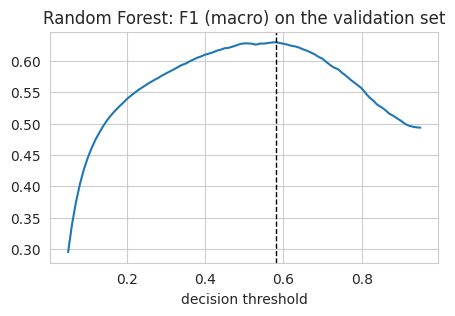

Threshold chosen on the validation set: 0.58


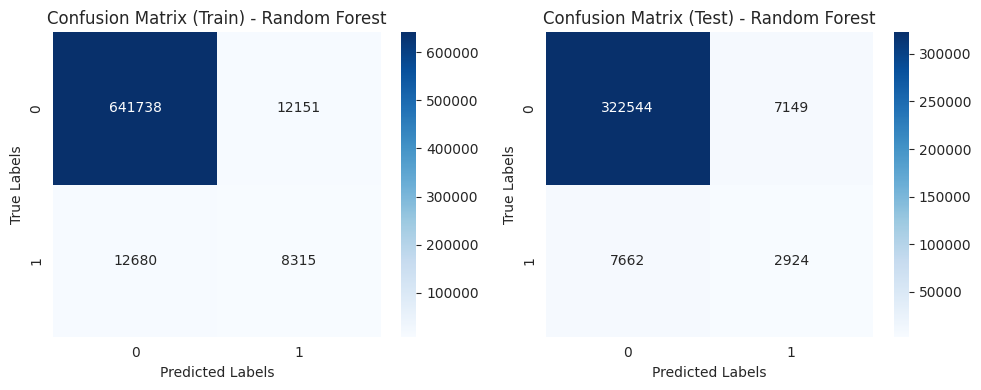

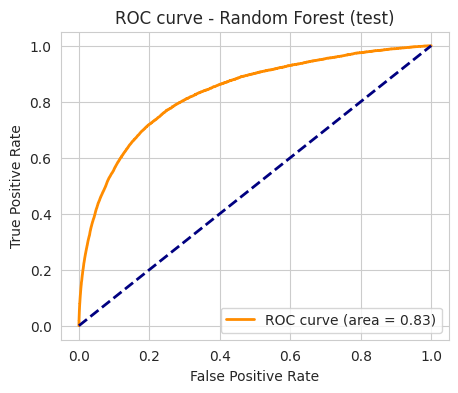

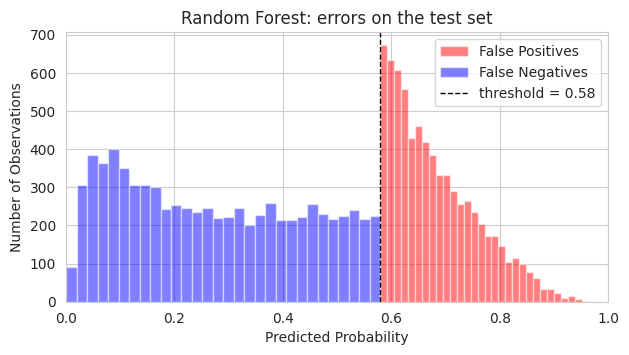

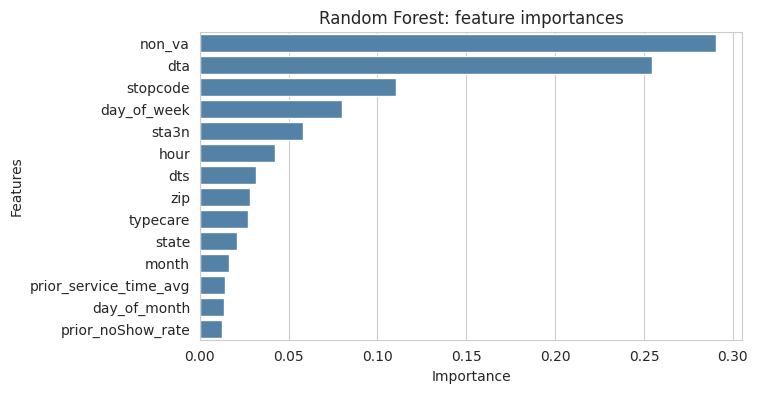

,Train,Test
Metric,,
Recall,0.6887,0.6273
AUC,0.9203,0.8321
Accuracy,0.9632,0.9565
Precision,0.6935,0.6335
F1 Score,0.6911,0.6303


In [6]:
run("Random Forest", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE), GRID_RF)
evaluate("Random Forest")

<a name="2.2"></a>
### 2.2 - XGBoost

XGBoost: trained in 64.5 min
Best hyperparameters: {'gamma': 0.3, 'learning_rate': 0.01, 'max_depth': 20, 'min_child_weight': 2, 'n_estimators': 1000, 'reg_alpha': 0.2, 'subsample': 0.4}


,params,mean_test_score,std_test_score,mean_fit_time
0,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.639407,0.002570,292.835515
1,"{'gamma': 0.3, 'learning_rate': 0.01, 'max_dep...",0.637701,0.001887,341.329772
3,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.628760,0.002744,242.296517
2,"{'gamma': 0.3, 'learning_rate': 0.1, 'max_dept...",0.626189,0.002621,185.885262


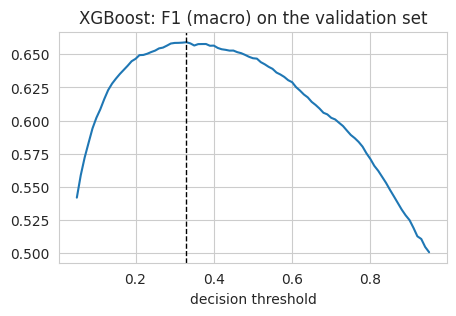

Threshold chosen on the validation set: 0.33


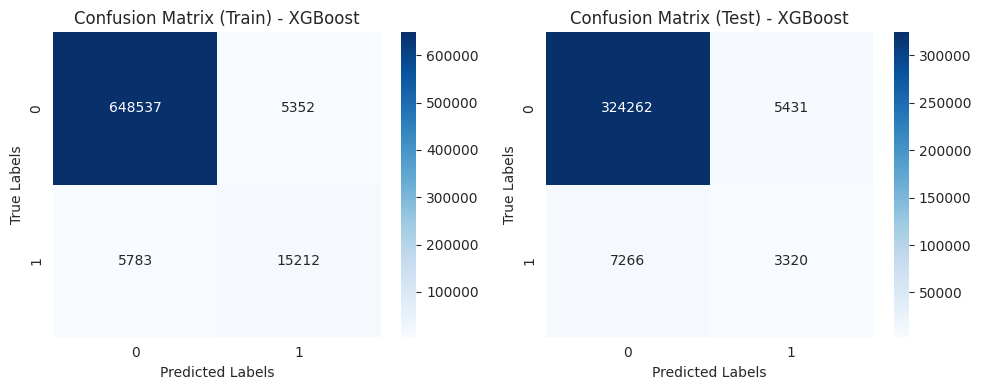

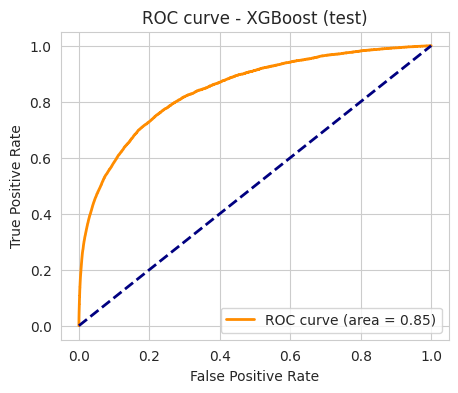

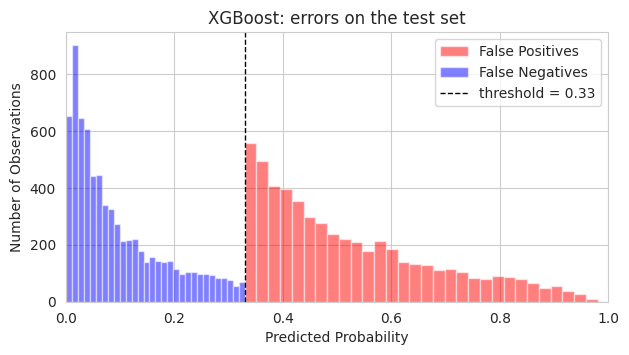

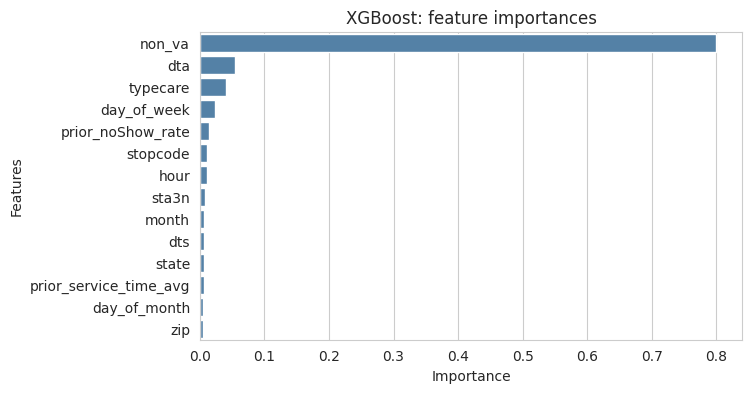

,Train,Test
Metric,,
Recall,0.8582,0.6486
AUC,0.9872,0.8453
Accuracy,0.9835,0.9627
Precision,0.8655,0.6787
F1 Score,0.8618,0.6621


In [7]:
run("XGBoost", xgb.XGBClassifier(objective="binary:logistic", scale_pos_weight=XGB_SCALE_POS_WEIGHT,
                                 tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), GRID_XGB)
evaluate("XGBoost")

<a name="2.3"></a>
### 2.3 - AdaBoost

AdaBoost: trained in 27.9 min
Best hyperparameters: {'learning_rate': 0.1, 'n_estimators': 100}


,params,mean_test_score,std_test_score,mean_fit_time
1,"{'learning_rate': 0.1, 'n_estimators': 100}",0.591278,0.003554,221.021096
0,"{'learning_rate': 0.05, 'n_estimators': 100}",0.576953,0.003866,219.284703


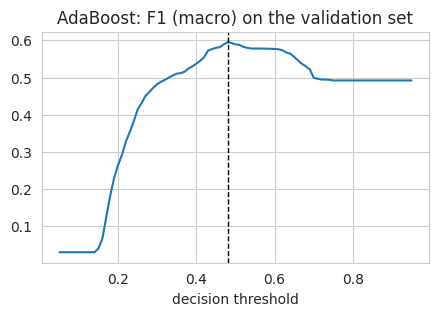

Threshold chosen on the validation set: 0.48


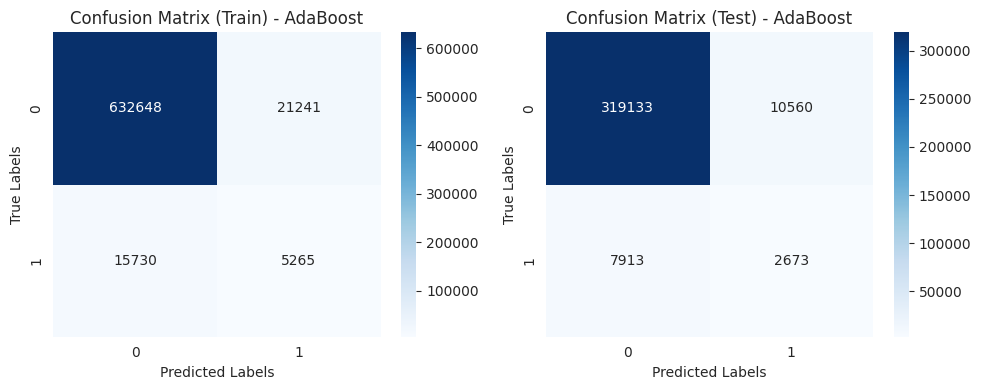

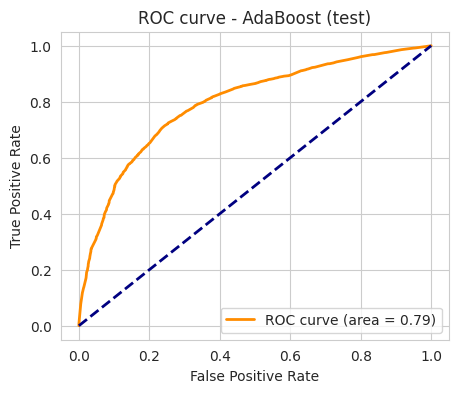

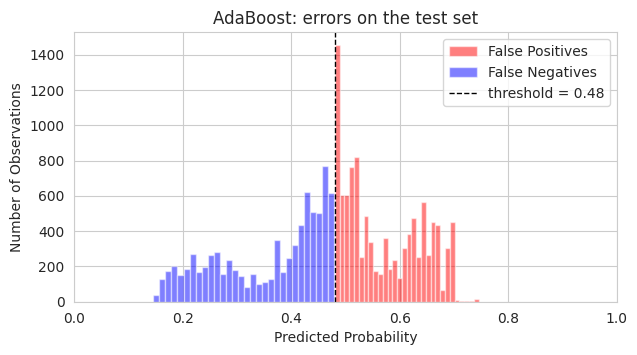

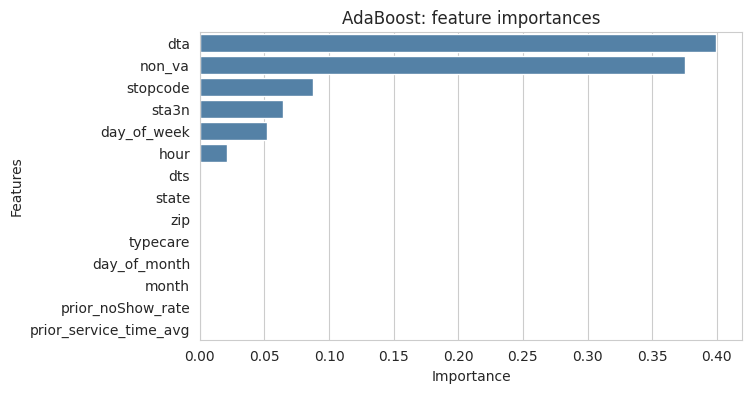

,Train,Test
Metric,,
Recall,0.6091,0.6102
AUC,0.7926,0.7949
Accuracy,0.9452,0.9457
Precision,0.5872,0.5889
F1 Score,0.5966,0.5982


In [8]:
run("AdaBoost", AdaBoostClassifier(random_state=RANDOM_STATE), GRID_ADA)
evaluate("AdaBoost")

<a name="2.4"></a>
### 2.4 - MLP

> **Correction.** In the paper the MLP stopped when its loss on the **test** set stopped improving (`validation_data=(X_test, y_test)`), so the test set took part in the training. Here it stops on 10 % of its own training data (`early_stopping=True`).

MLP: trained in 5.1 min


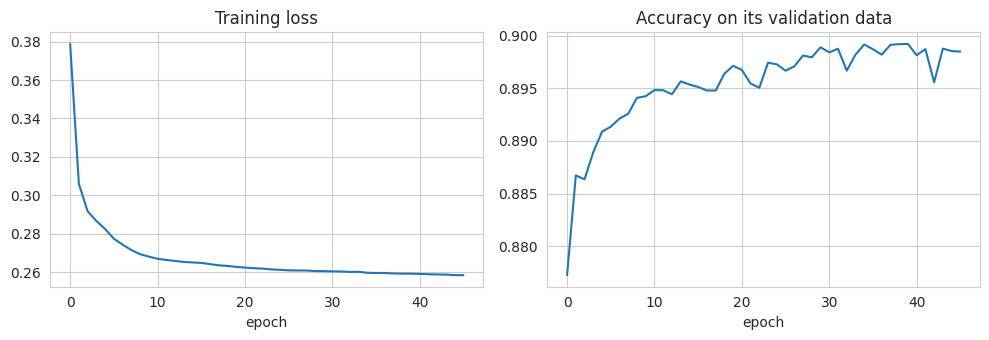

Stopped after 46 epochs


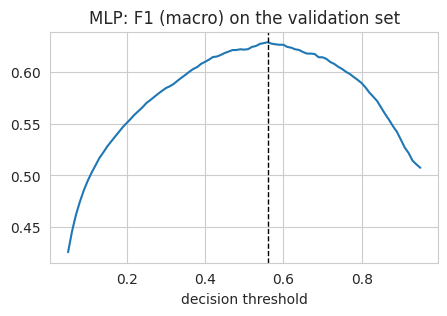

Threshold chosen on the validation set: 0.56


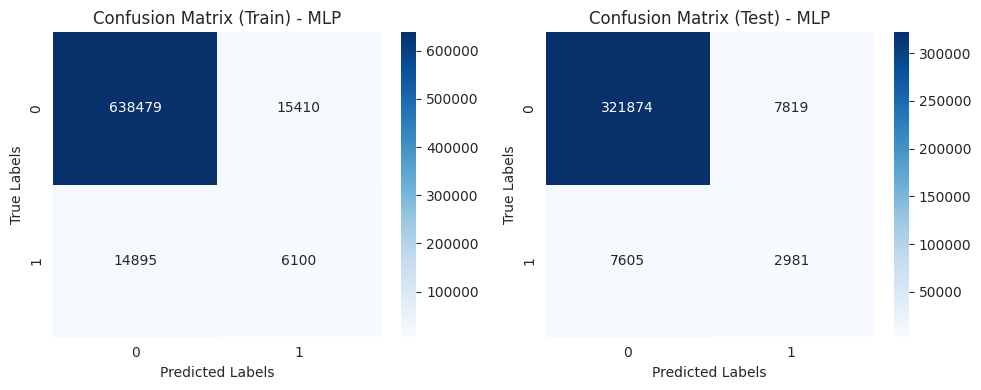

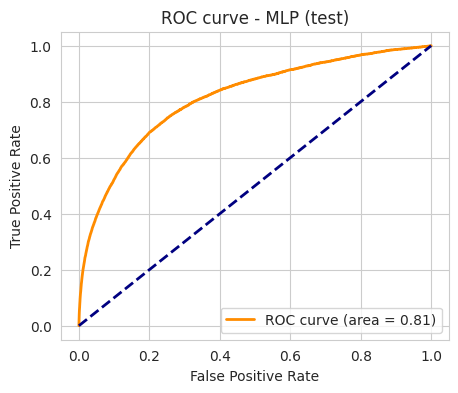

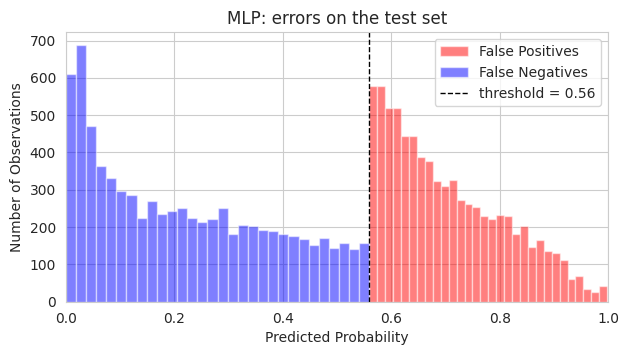

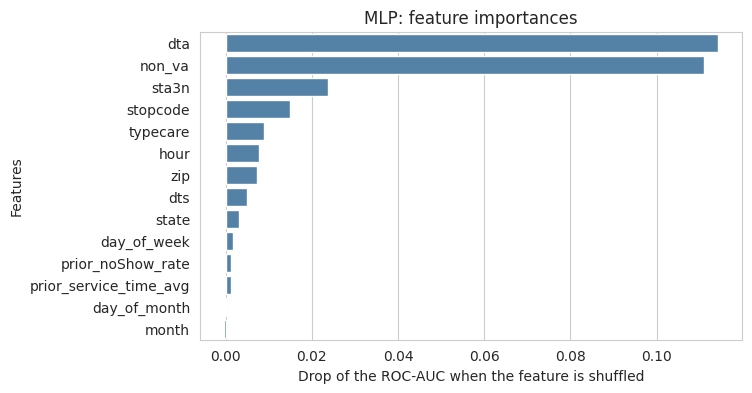

,Train,Test
Metric,,
Recall,0.6335,0.6289
AUC,0.8187,0.8141
Accuracy,0.9551,0.9547
Precision,0.6304,0.6265
F1 Score,0.6319,0.6277


In [9]:
run("MLP", MLPClassifier(**MLP_PARAMS), None)
mlp = models["MLP"].named_steps["model"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(mlp.loss_curve_); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(mlp.validation_scores_); ax[1].set_title("Accuracy on its validation data"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print(f"Stopped after {mlp.n_iter_} epochs")
evaluate("MLP")

<a name="3"></a>
## 3 - Comparison of the models

Test metrics of the four models, next to the metrics of the conference paper. The differences come from the changes listed at the top (mainly the two predictors removed, which were known only after the consultation).

In [10]:
test_metrics = pd.DataFrame({name: res["Test"] for name, res in results.items()})
comparison = pd.concat({"this study": test_metrics, "conference paper": PAPER_TEST_METRICS[test_metrics.columns]}, axis=1)
comparison = comparison.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(comparison.round(4))
test_metrics.loc["Threshold"] = pd.Series(thresholds)
test_metrics.round(4)

AdaBoost                         MLP                   \
          this study conference paper this study conference paper   
Recall        0.6102           0.5275     0.6289           0.6409   
AUC           0.7949           0.8147     0.8141           0.7974   
Accuracy      0.9457           0.9678     0.9547           0.9504   
Precision     0.5889           0.6767     0.6265           0.6166   
F1 Score      0.5982           0.5422     0.6277           0.6274   

          Random Forest                     XGBoost                   
             this study conference paper this study conference paper  
Recall           0.6273           0.7079     0.6486           0.6691  
AUC              0.8321           0.8307     0.8453           0.8649  
Accuracy         0.9565           0.8988     0.9627           0.9678  
Precision        0.6335           0.5686     0.6787           0.7277  
F1 Score         0.6303           0.5911     0.6621           0.6936

,Random Forest,XGBoost,AdaBoost,MLP
Metric,,,,
Recall,0.6273,0.6486,0.6102,0.6289
AUC,0.8321,0.8453,0.7949,0.8141
Accuracy,0.9565,0.9627,0.9457,0.9547
Precision,0.6335,0.6787,0.5889,0.6265
F1 Score,0.6303,0.6621,0.5982,0.6277
Threshold,0.5800,0.3300,0.4800,0.5600


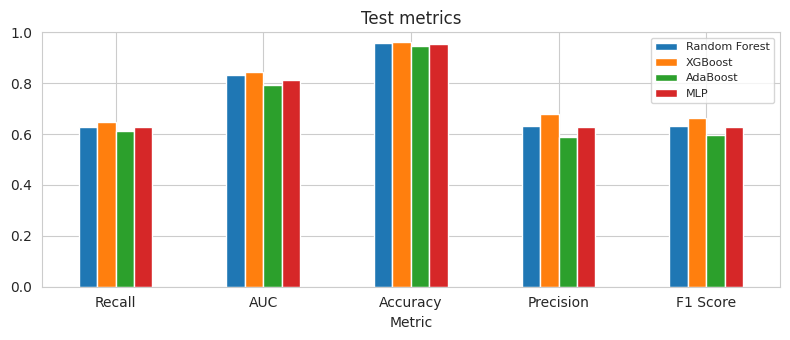

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
test_metrics.drop("Threshold").plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_title("Test metrics"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The model used for the scheduling is the one with the best F1 score on the **validation** set (the test set does not take part in the choice).

In [12]:
val_f1 = pd.Series({name: f1_score(y_val, (probas[name]["val"] >= thresholds[name]).astype(int), average="macro")
                    for name in models})
print("F1 (macro) on the validation set:"); print(val_f1.round(4).to_string())
BEST = val_f1.idxmax()
print(f"\nModel used for the scheduling: {BEST}")

F1 (macro) on the validation set:
Random Forest    0.6296
XGBoost          0.6591
AdaBoost         0.5949
MLP              0.6288

Model used for the scheduling: XGBoost


<a name="4"></a>
## 4 - Probabilities for the scheduling model

The scheduling model (notebook 04) needs the **probability** that each patient comes, not only a yes/no prediction. The models were trained on data where no-shows are much more frequent than in reality (SMOTE, class weights), so their scores are not probabilities at the real rate. Platt scaling (`platt_scaling`; Platt, 1999) fits a logistic regression with two parameters on the **validation** set, from the score of the model to the observed no-show. It is monotone, so the ranking of the consultations and the AUC are unchanged. The reliability diagram below compares the scores before and after on the validation set: well-calibrated probabilities lie on the diagonal; the test set then gets the calibrated probabilities.

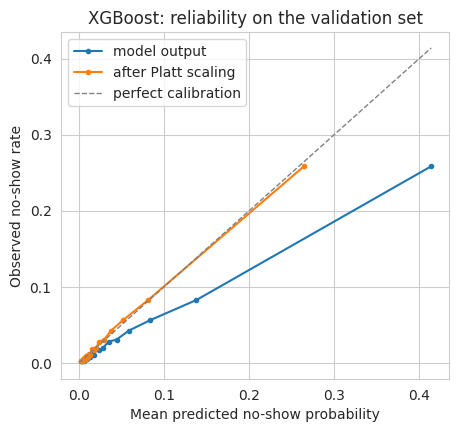

Mean no-show probability on validation: model 0.0472, calibrated 0.0311, observed rate 0.0311
Mean no-show probability on test: calibrated 0.0309, observed rate 0.0311


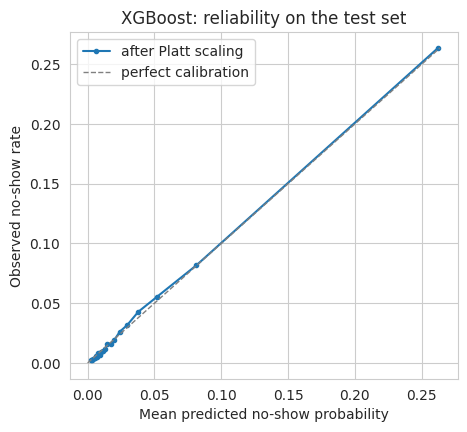

In [13]:
calibrate = platt_scaling(probas[BEST]["val"], y_val)
val_calibrated = calibrate(probas[BEST]["val"])
plot_reliability(y_val, {"model output": probas[BEST]["val"], "after Platt scaling": val_calibrated},
                 RELIABILITY_BINS, f"{BEST}: reliability on the validation set")
print(f"Mean no-show probability on validation: model {probas[BEST]['val'].mean():.4f}, "
      f"calibrated {val_calibrated.mean():.4f}, observed rate {y_val.mean():.4f}")
test_calibrated = calibrate(probas[BEST]["test"])
print(f"Mean no-show probability on test: calibrated {test_calibrated.mean():.4f}, observed rate {y_test.mean():.4f}")
plot_reliability(y_test, {"after Platt scaling": test_calibrated}, RELIABILITY_BINS, f"{BEST}: reliability on the test set")

Export, for every consultation of the test set (identified by its row in `data_prep.parquet`): its calibrated no-show probability and whether it was actually a no-show.

In [14]:
test_scores = pd.DataFrame({
    "row": rows_test,
    "p_noshow": test_calibrated,
    "NoShow": y_test,
})
test_scores.to_parquet(SCORES_PATH, index=False)
print(f"Saved {SCORES_PATH}: {len(test_scores):,} test consultations, model {BEST}")
test_scores.drop(columns="row").describe()

Saved ../runs/pilot_test_scores.parquet: 340,279 test consultations, model XGBoost


,p_noshow,NoShow
count,340279.000000,340279.000000
mean,0.030921,0.031110
std,0.068159,0.173615
min,0.000542,0.000000
25%,0.006457,0.000000
50%,0.012123,0.000000
75%,0.026480,0.000000
max,0.957640,1.000000
